# Multiwavelength Analysis of NGC 7331

A reproducible study combining WISE mid-infrared photometry with THINGS 21-cm neutral-hydrogen observations. The analysis derives physical fluxes and luminosities, tests distance scaling, examines infrared colours, and maps the gas distribution and kinematics of NGC 7331.

## Scientific questions

- How do the WISE measurements translate into calibrated flux densities and band luminosities?
- How does flux change with distance when comparing sources of similar intrinsic brightness?
- What do WISE colours suggest about the infrared-emitting populations?
- What do the HI moment maps reveal about the gas distribution, ordered velocity field, and velocity dispersion?

## Measurement assumptions and calibration

The columns `W1mag_x` through `W4mag_x` contain values typical of catalogue apparent magnitudes, so they are treated here as calibrated WISE Vega magnitudes—not as absolute magnitudes. The accompanying `D_L` values are on the centimetre scale (their range corresponds to plausible nearby-galaxy distances); the notebook converts them to parsecs and metres explicitly. Confirm these two assumptions against the original catalogue documentation if it becomes available.

WISE flux densities use the published Vega zero-magnitude flux densities. Absolute magnitudes use the distance modulus, and monochromatic luminosities are reported as `nu L_nu` in watts. Extinction, K-corrections, and bandpass colour corrections are not applied, so these are approximate rest-frame luminosities.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS

possible_roots = (Path.cwd(), Path.cwd().parent)
PROJECT_ROOT = next(
    (root.resolve() for root in possible_roots
     if (root / "data" / "WISE_set1.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/WISE_set1.csv. Open the notebook from "
        "the project root or its notebooks/ directory."
    )

DATA_DIR = PROJECT_ROOT / "data"
FITS_DIR = PROJECT_ROOT / "FITS"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\user\Desktop\4281148_PHY327_Practical1


## 1. WISE catalogue and data quality

First, check the catalogue dimensions, required measurements, missing values, and distance range before deriving physical quantities.

In [2]:
wise_raw = pd.read_csv(DATA_DIR / "WISE_set1.csv")
magnitude_columns = [f"{band}mag_x" for band in ("W1", "W2", "W3", "W4")]
required_columns = ["Source_id", "RA", "DEC", "D_L", *magnitude_columns]
missing_columns = sorted(set(required_columns) - set(wise_raw.columns))
if missing_columns:
    raise KeyError(f"Required catalogue columns are missing: {missing_columns}")

wise = wise_raw.dropna(subset=required_columns).copy()
if (wise["D_L"] <= 0).any():
    raise ValueError("Every luminosity distance must be positive.")

print(f"Catalogue rows: {len(wise_raw):,}")
print(f"Complete rows used: {len(wise):,}")
print(f"Rows excluded for missing required data: {len(wise_raw) - len(wise):,}")
wise.head()

Catalogue rows: 1,000
Complete rows used: 1,000
Rows excluded for missing required data: 0


,Source_id,RA,DEC,W1mag_x,W2mag_x,W3mag_x,W4mag_x,D_L
0,49180,343.290689,-35.161662,13.226,13.080,9.113,7.505,8.572425e+24
1,51522,349.538175,-34.304144,14.978,14.647,10.297,7.144,1.312625e+25
2,33937,334.572372,-33.139798,15.597,15.356,12.571,8.990,1.495910e+26
3,29396,350.426624,-31.174298,15.880,15.825,12.246,8.986,9.009021e+25
4,48100,342.274004,-35.134989,14.291,14.043,10.101,8.612,1.785041e+25


## 2. WISE photometry: magnitudes to luminosity

For each Vega magnitude `m`, the catalogue flux density is `F_nu = F_nu,0 * 10**(-0.4 m)`. The absolute magnitude is `M = m - 5 log10(d / 10 pc)`. Combining the calibrated flux density with the luminosity distance gives `nu L_nu = 4 pi d_L**2 nu F_nu`.

This uses a band-specific calibration; it avoids treating the Sun's bolometric luminosity and optical absolute magnitude as if they were WISE-band calibrations. WISE wavelengths and Vega zero-points follow the [WISE All-Sky photometric calibration documentation](https://wise2.ipac.caltech.edu/docs/release/allsky/expsup/sec4_4h.html).

In [3]:
PC_TO_CM = 3.085677581e18
CM_TO_M = 1e-2
JY_TO_W_M2_HZ = 1e-26
C_M_S = 299_792_458
WISE_ZERO_POINT_JY = {"W1": 309.540, "W2": 171.787, "W3": 31.674, "W4": 8.363}
WISE_WAVELENGTH_UM = {"W1": 3.4, "W2": 4.6, "W3": 12.0, "W4": 22.0}

wise["D_L_pc"] = wise["D_L"] / PC_TO_CM
wise["D_L_Mpc"] = wise["D_L_pc"] / 1e6
wise["D_L_m"] = wise["D_L"] * CM_TO_M
wise["Distance_modulus"] = 5 * np.log10(wise["D_L_pc"] / 10)

for band in ("W1", "W2", "W3", "W4"):
    apparent_magnitude = wise[f"{band}mag_x"]
    frequency_hz = C_M_S / (WISE_WAVELENGTH_UM[band] * 1e-6)
    wise[f"AbsMag_{band}"] = apparent_magnitude - wise["Distance_modulus"]
    wise[f"Flux_{band}_Jy"] = (
        WISE_ZERO_POINT_JY[band] * 10 ** (-0.4 * apparent_magnitude)
    )
    wise[f"nuLnu_{band}_W"] = (
        4 * np.pi * wise["D_L_m"] ** 2
        * frequency_hz * wise[f"Flux_{band}_Jy"] * JY_TO_W_M2_HZ
    )

print("Luminosity-distance range [Mpc]:", wise["D_L_Mpc"].quantile([0, .5, 1]).round(2).to_dict())
wise[["Source_id", "D_L_Mpc", "W1mag_x", "AbsMag_W1", "Flux_W1_Jy", "nuLnu_W1_W"]].head()

Luminosity-distance range [Mpc]: {0.0: 0.45, 0.5: 35.26, 1.0: 348.2}


,Source_id,D_L_Mpc,W1mag_x,AbsMag_W1,Flux_W1_Jy,nuLnu_W1_W
0,49180,2.778134,13.226,-13.992766,0.001586,1.291445e+32
1,51522,4.253928,14.978,-13.165951,0.000316,6.030452e+31
2,33937,48.479153,15.597,-17.830775,0.000179,4.428734e+33
3,29396,29.196250,15.880,-16.446635,0.000138,1.237724e+33
4,48100,5.784924,14.291,-14.520488,0.000595,2.099737e+32


The distance modulus and band calibrations are now explicit and reproducible. A source's WISE apparent magnitude is not itself an absolute magnitude; distance is needed before comparing intrinsic brightness.

In [4]:
wise_band_summary = pd.DataFrame([
    {
        "Band": band,
        "Median absolute magnitude": wise[f"AbsMag_{band}"].median(),
        "Median flux density [mJy]": 1e3 * wise[f"Flux_{band}_Jy"].median(),
        "Median nuLnu [W]": wise[f"nuLnu_{band}_W"].median(),
    }
    for band in ("W1", "W2", "W3", "W4")
]).set_index("Band")
wise_band_summary.round(3)

,Median absolute magnitude,Median flux density [mJy],Median nuLnu [W]
Band,,,
W1,-17.254,0.247,2.603939e+33
W2,-17.513,0.178,1.355388e+33
W3,-20.923,0.513,2.215861e+33
W4,-24.081,3.053,5.848980e+33


### Intrinsic brightness across the four bands

The following figure compares distance-corrected absolute magnitude with `nu L_nu`. Because both quantities are derived from the same photometry and calibration, the tight trend is a consistency check on the magnitude-to-luminosity conversion—not an independent discovery about the sample.

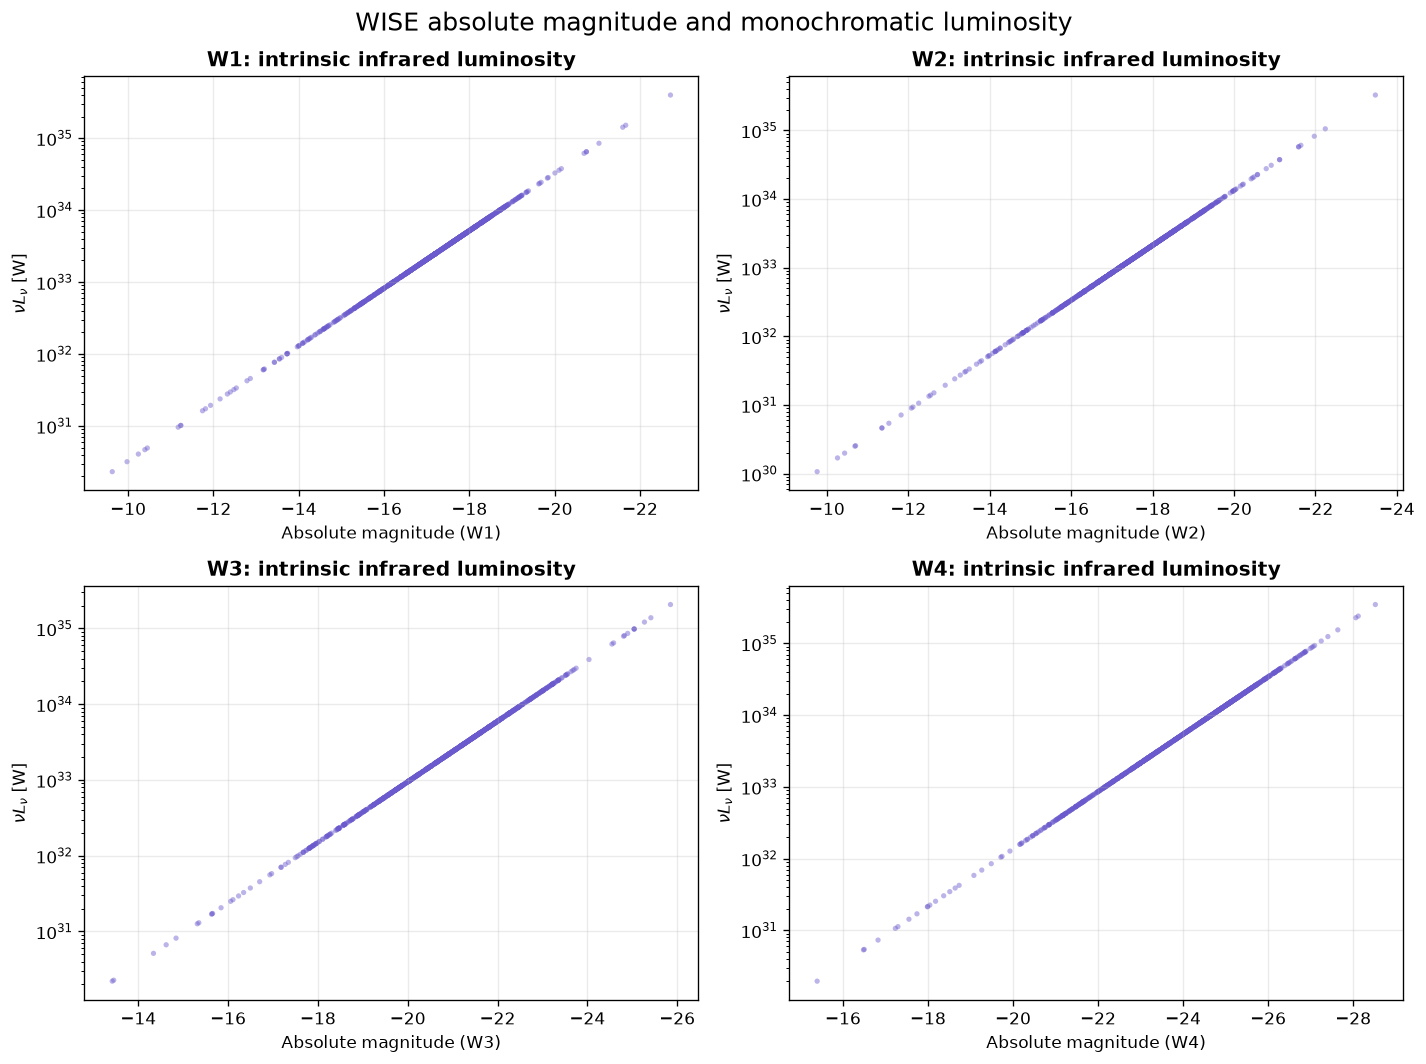

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=False)
for ax, band in zip(axes.flat, ("W1", "W2", "W3", "W4")):
    ax.scatter(wise[f"AbsMag_{band}"], wise[f"nuLnu_{band}_W"],
               s=10, alpha=0.45, color="slateblue", edgecolors="none")
    ax.set_yscale("log")
    ax.set_xlabel(f"Absolute magnitude ({band})")
    ax.set_ylabel(r"$\nu L_\nu$ [W]")
    ax.set_title(f"{band}: intrinsic infrared luminosity")
    ax.invert_xaxis()
fig.suptitle("WISE absolute magnitude and monochromatic luminosity", fontsize=15)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "wise_luminosity.png", dpi=200, bbox_inches="tight")
fig.savefig(RESULTS_DIR / "wise_luminosity.pdf", bbox_inches="tight")
plt.show()

Brighter absolute magnitudes correspond to larger `nu L_nu`, as expected from the magnitude definition. Band luminosities are monochromatic estimates; they are not bolometric luminosities.

## 3. Flux-distance relation

The inverse-square law predicts `F_nu proportional to d_L**-2` for sources with the same intrinsic luminosity. The whole catalogue contains a mix of intrinsic brightnesses, so the next plot distinguishes all sources from a controlled subset within 0.5 magnitude of the median absolute magnitude in each band.

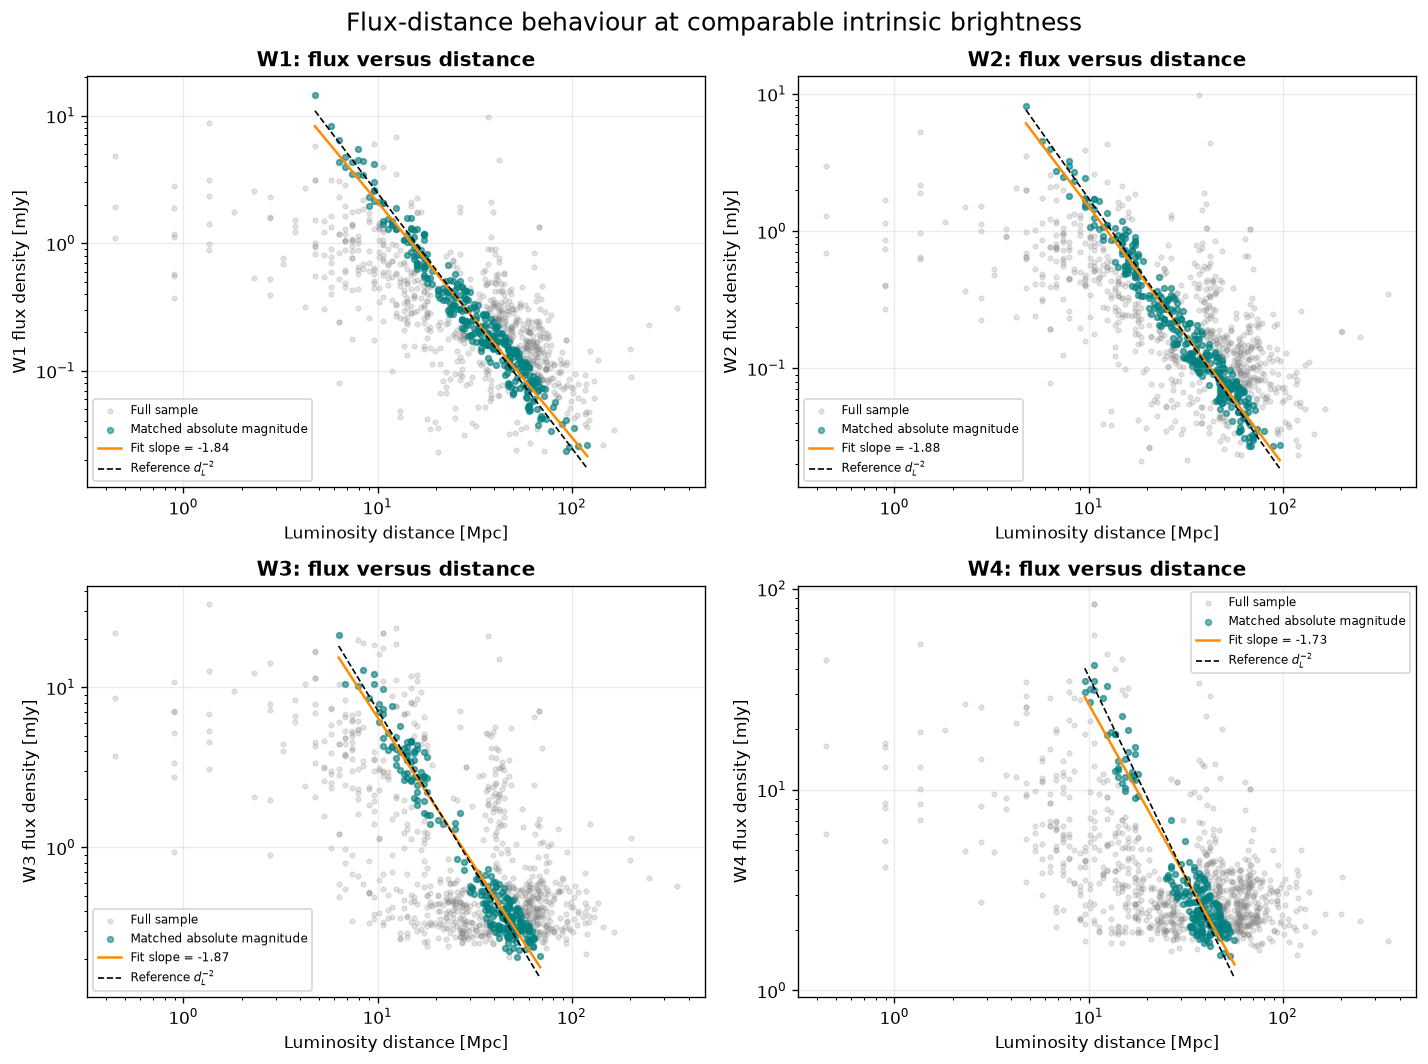

,Matched sources,Fitted log-log slope,R squared
Band,,,
W1,338,-1.845,0.955
W2,330,-1.879,0.955
W3,256,-1.865,0.949
W4,203,-1.726,0.895


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
distance_slopes = []
HALF_WIDTH_MAG = 0.5

for ax, band in zip(axes.flat, ("W1", "W2", "W3", "W4")):
    mag = wise[f"AbsMag_{band}"]
    flux_jy = wise[f"Flux_{band}_Jy"]
    distance_mpc = wise["D_L_Mpc"]
    matched = (mag - mag.median()).abs() <= HALF_WIDTH_MAG
    if matched.sum() < 3:
        raise ValueError(f"Too few matched sources to fit the {band} distance trend.")

    x = np.log10(distance_mpc[matched])
    y = np.log10(flux_jy[matched])
    slope, intercept = np.polyfit(x, y, 1)
    fitted = 10 ** (intercept + slope * x)
    ss_total = np.sum((y - y.mean()) ** 2)
    r_squared = 1 - np.sum((y - (intercept + slope * x)) ** 2) / ss_total
    distance_slopes.append({"Band": band, "Matched sources": int(matched.sum()),
                            "Fitted log-log slope": slope, "R squared": r_squared})

    ax.scatter(distance_mpc, flux_jy * 1e3, s=8, alpha=0.2,
               color="gray", label="Full sample")
    ax.scatter(distance_mpc[matched], flux_jy[matched] * 1e3, s=12,
               alpha=0.55, color="teal", label="Matched absolute magnitude")
    order = np.argsort(distance_mpc[matched].to_numpy())
    matched_distances = distance_mpc[matched].to_numpy()[order]
    ax.plot(matched_distances, fitted.to_numpy()[order] * 1e3,
            color="darkorange", linewidth=1.5,
            label=f"Fit slope = {slope:.2f}")
    reference = flux_jy[matched].median() * (
        matched_distances / distance_mpc[matched].median()
    ) ** -2
    ax.plot(matched_distances, reference * 1e3, "k--", linewidth=1,
            label=r"Reference $d_L^{-2}$")
    ax.set(xscale="log", yscale="log", xlabel="Luminosity distance [Mpc]",
           ylabel=f"{band} flux density [mJy]", title=f"{band}: flux versus distance")
    ax.legend(fontsize=7)

fig.suptitle("Flux-distance behaviour at comparable intrinsic brightness", fontsize=15)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "wise_flux_distance.png", dpi=200, bbox_inches="tight")
fig.savefig(RESULTS_DIR / "wise_flux_distance.pdf", bbox_inches="tight")
plt.show()

distance_slope_summary = pd.DataFrame(distance_slopes).set_index("Band")
distance_slope_summary.round(3)

The fitted slopes quantify how closely the matched samples follow the inverse-square reference. Scatter remains because the magnitude window is finite and because the sample includes measurement uncertainty and astrophysical variation. These are descriptive fits, not a cosmological distance measurement.

## 4. WISE infrared colours

Magnitude differences provide distance-independent colour diagnostics. `W1-W2` is sensitive to hot dust and AGN emission; `W2-W3` responds to PAH and warm-dust emission. The commonly used `W1-W2 > 0.5` threshold is shown as a candidate-selection guide, not a definitive classification.

In [7]:
wise["W1_W2"] = wise["W1mag_x"] - wise["W2mag_x"]
wise["W2_W3"] = wise["W2mag_x"] - wise["W3mag_x"]
wise["W3_W4"] = wise["W3mag_x"] - wise["W4mag_x"]
wise["W1_W4"] = wise["W1mag_x"] - wise["W4mag_x"]
wise["AGN_colour_candidate"] = wise["W1_W2"] > 0.5

candidate_count = int(wise["AGN_colour_candidate"].sum())
candidate_fraction = wise["AGN_colour_candidate"].mean()
print(f"Sources above W1-W2 = 0.5: {candidate_count:,} / {len(wise):,} "
      f"({candidate_fraction:.1%}); these are colour-selected candidates, not confirmed AGN.")
wise[["Source_id", "W1_W2", "W2_W3", "W3_W4", "W1_W4"]].describe().round(3)

Sources above W1-W2 = 0.5: 230 / 1,000 (23.0%); these are colour-selected candidates, not confirmed AGN.


,Source_id,W1_W2,W2_W3,W3_W4,W1_W4
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,24672.279,0.334,3.374,3.037,6.745
std,12559.325,0.304,0.786,0.698,0.905
min,51.000,-0.480,-0.071,1.123,2.989
25%,15036.000,0.143,2.908,2.472,6.191
50%,25726.000,0.280,3.525,3.216,6.754
75%,34465.750,0.471,3.937,3.577,7.382
max,54901.000,1.613,5.688,4.402,9.344


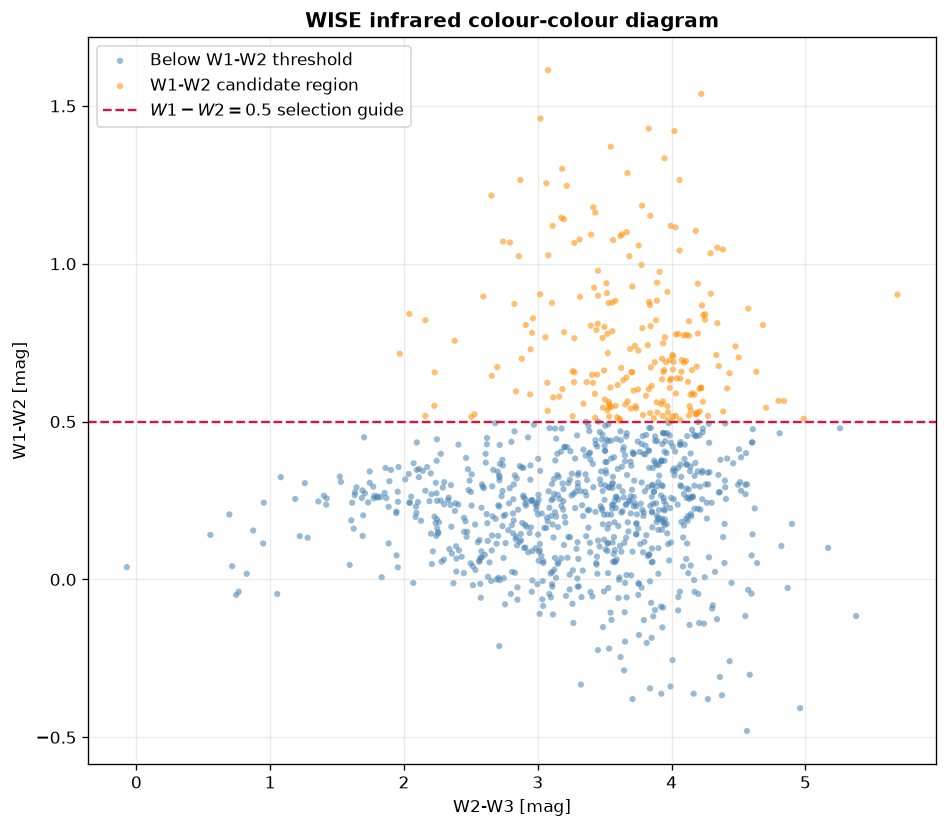

In [8]:
fig, ax = plt.subplots(figsize=(8, 7))
for is_candidate, label, color in (
    (False, "Below W1-W2 threshold", "steelblue"),
    (True, "W1-W2 candidate region", "darkorange"),
):
    sample = wise[wise["AGN_colour_candidate"] == is_candidate]
    ax.scatter(sample["W2_W3"], sample["W1_W2"], s=14, alpha=0.55,
               color=color, edgecolors="none", label=label)
ax.axhline(0.5, color="crimson", linestyle="--", linewidth=1.4,
           label=r"$W1-W2=0.5$ selection guide")
ax.set(xlabel="W2-W3 [mag]", ylabel="W1-W2 [mag]",
       title="WISE infrared colour-colour diagram")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "wise_colour_colour.png", dpi=200, bbox_inches="tight")
fig.savefig(RESULTS_DIR / "wise_colour_colour.pdf", bbox_inches="tight")
plt.show()

Sources above the horizontal guide have redder `W1-W2` colours that can indicate an AGN-heated dust component. Redder `W2-W3` colours point to stronger mid-infrared dust and PAH emission. Spectroscopy or additional multiwavelength information is needed to confirm individual classifications.

## 5. HI moment maps of NGC 7331

The THINGS FITS files store four-dimensional arrays with singleton Stokes and spectral axes. The two-dimensional sky image is extracted from `[0, 0, :, :]` and displayed using the FITS World Coordinate System (WCS).

- **Moment 0** integrates the 21-cm emission and traces neutral gas.
- **Moment 1** is the intensity-weighted line-of-sight velocity.
- **Moment 2** is the intensity-weighted velocity dispersion.

The header reports Moment 0 in Jy beam⁻¹ m s⁻¹ and Moments 1 and 2 in m s⁻¹. The notebook converts these to Jy beam⁻¹ km s⁻¹ and km s⁻¹.

In [9]:
def load_moment_map(filename):
    """Load a two-dimensional map and its original FITS header."""
    with fits.open(FITS_DIR / filename) as hdul:
        data = np.asarray(hdul[0].data[0, 0, :, :], dtype=float)
        header = hdul[0].header.copy()
    return data, header

mom0_raw, header0 = load_moment_map("NGC_7331_NA_MOM0_THINGS.FITS")
mom1_raw, header1 = load_moment_map("NGC_7331_NA_MOM1_THINGS.FITS")
mom2_raw, header2 = load_moment_map("NGC_7331_NA_MOM2_THINGS.FITS")

moment0 = mom0_raw / 1000.0
moment1 = mom1_raw / 1000.0
moment2 = mom2_raw / 1000.0

positive_moment0 = moment0[np.isfinite(moment0) & (moment0 > 0)]
if positive_moment0.size == 0:
    raise ValueError("The Moment 0 map contains no positive finite emission pixels.")
emission_threshold = np.nanpercentile(positive_moment0, 40)
emission_mask = np.isfinite(moment0) & (moment0 >= emission_threshold) & (moment0 > 0)
moment1_emission = np.where(emission_mask & np.isfinite(moment1), moment1, np.nan)
moment2_emission = np.where(emission_mask & np.isfinite(moment2), moment2, np.nan)

print("FITS input units:", header0.get("BUNIT"), header1.get("BUNIT"), header2.get("BUNIT"))
print("Map dimensions:", mom0_raw.shape, mom1_raw.shape, mom2_raw.shape)
print(f"Emission-mask pixels: {emission_mask.sum():,}")

FITS input units: JY/B*M/S METR/SEC METR/SEC
Map dimensions: (1024, 1024) (1024, 1024) (1024, 1024)
Emission-mask pixels: 56,134


### Neutral-hydrogen distribution — Moment 0

The intensity map is displayed in integrated flux per synthesized beam. A percentile-based display mask suppresses weak positive background pixels; the colour scale is limited by the 99th percentile of positive emission so a few bright pixels do not hide the large-scale structure.

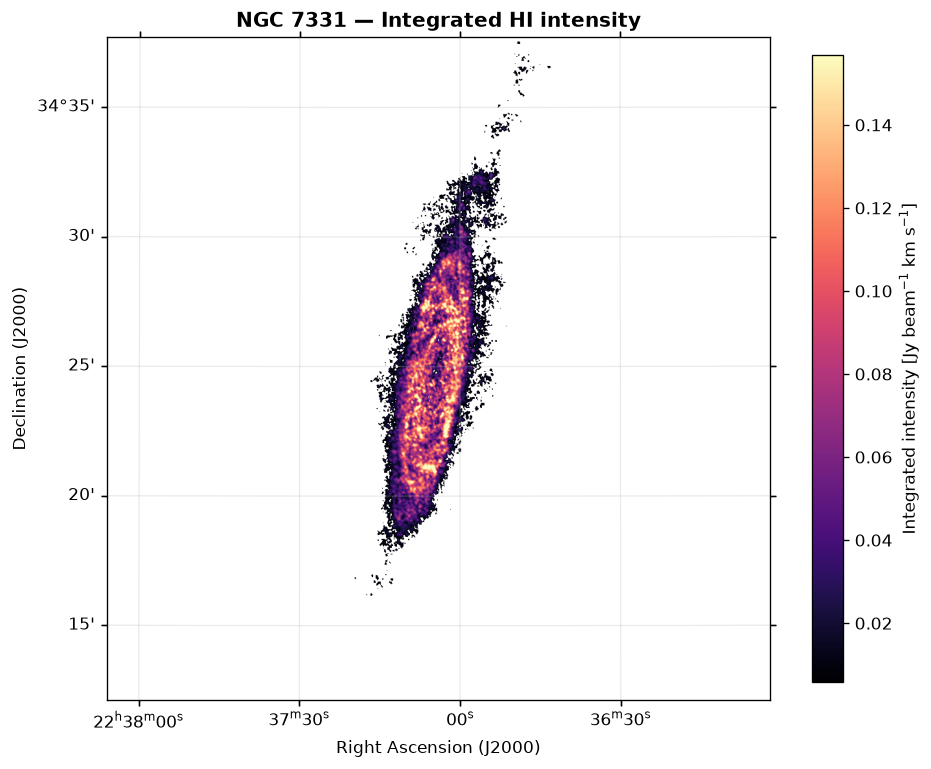

In [10]:
fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(projection=WCS(header0, naxis=2))
moment0_display = np.where(emission_mask, moment0, np.nan)
moment0_cmap = plt.get_cmap("magma").copy()
moment0_cmap.set_bad("white")
im = ax.imshow(moment0_display, origin="lower", cmap=moment0_cmap,
                vmax=np.nanpercentile(positive_moment0, 99))
ax.set(xlabel="Right Ascension (J2000)", ylabel="Declination (J2000)",
       title="NGC 7331 — Integrated HI intensity")
cb = fig.colorbar(im, ax=ax, shrink=0.84)
cb.set_label(r"Integrated intensity [Jy beam$^{-1}$ km s$^{-1}$]")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ngc7331_moment0.png", dpi=220, bbox_inches="tight")
fig.savefig(RESULTS_DIR / "ngc7331_moment0.pdf", bbox_inches="tight")
plt.show()

### Ordered gas motion — Moment 1

The intensity-weighted velocity map shows the receding and approaching sides of the rotating disk. Pixels outside the positive-emission mask are excluded from the display.

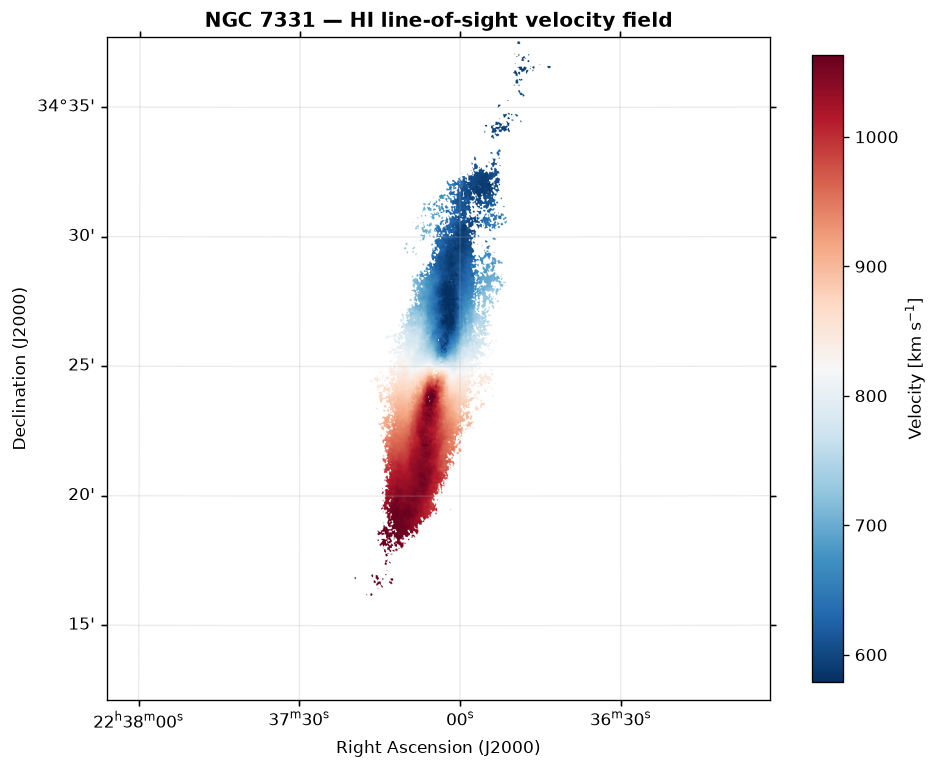

In [11]:
velocity_values = moment1_emission[np.isfinite(moment1_emission)]
fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(projection=WCS(header1, naxis=2))
velocity_cmap = plt.get_cmap("RdBu_r").copy()
velocity_cmap.set_bad("white")
im = ax.imshow(moment1_emission, origin="lower", cmap=velocity_cmap,
                vmin=np.nanpercentile(velocity_values, 1),
                vmax=np.nanpercentile(velocity_values, 99))
ax.set(xlabel="Right Ascension (J2000)", ylabel="Declination (J2000)",
       title="NGC 7331 — HI line-of-sight velocity field")
cb = fig.colorbar(im, ax=ax, shrink=0.84)
cb.set_label("Velocity [km s$^{-1}$]")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ngc7331_moment1.png", dpi=220, bbox_inches="tight")
fig.savefig(RESULTS_DIR / "ngc7331_moment1.pdf", bbox_inches="tight")
plt.show()

### Gas kinematics — Moment 2

Velocity dispersion measures the width of the local HI line profile. Larger values can arise from turbulence, unresolved motions, or line-of-sight blending; the moment map alone does not separate these effects.

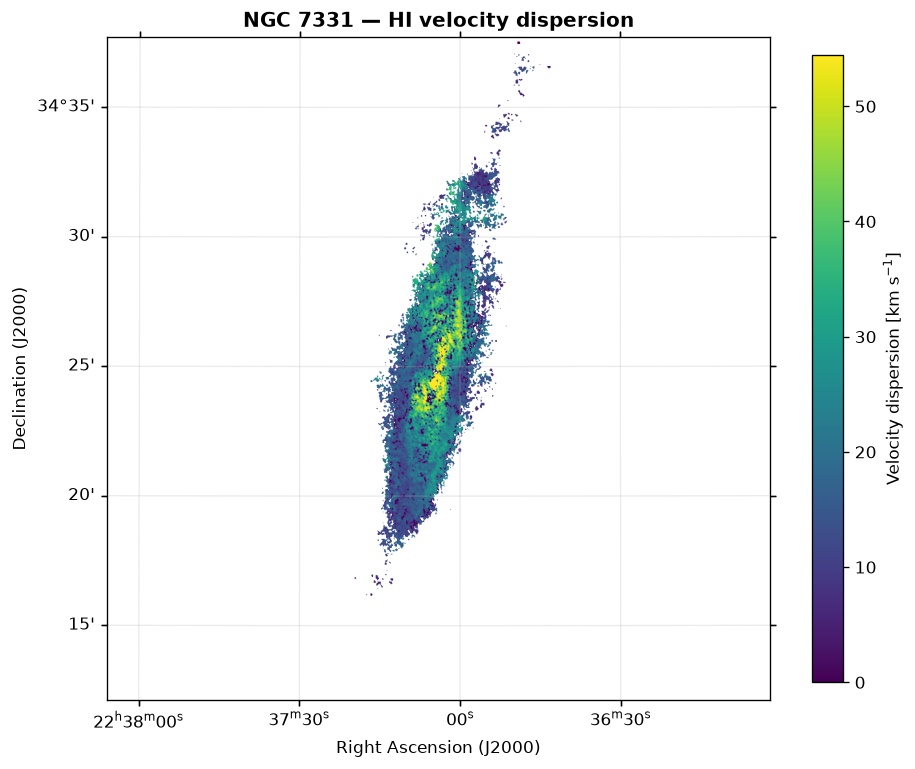

In [12]:
dispersion_values = moment2_emission[np.isfinite(moment2_emission) & (moment2_emission >= 0)]
if dispersion_values.size == 0:
    raise ValueError("No valid Moment 2 values were found in the HI emission mask.")
fig = plt.figure(figsize=(8, 7))
ax = plt.subplot(projection=WCS(header2, naxis=2))
dispersion_cmap = plt.get_cmap("viridis").copy()
dispersion_cmap.set_bad("white")
im = ax.imshow(moment2_emission, origin="lower", cmap=dispersion_cmap,
                vmin=0, vmax=np.nanpercentile(dispersion_values, 99))
ax.set(xlabel="Right Ascension (J2000)", ylabel="Declination (J2000)",
       title="NGC 7331 — HI velocity dispersion")
cb = fig.colorbar(im, ax=ax, shrink=0.84)
cb.set_label("Velocity dispersion [km s$^{-1}$]")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "ngc7331_moment2.png", dpi=220, bbox_inches="tight")
fig.savefig(RESULTS_DIR / "ngc7331_moment2.pdf", bbox_inches="tight")
plt.show()

### Quantitative summary of the HI maps

Percentiles are measured only within the Moment 0 emission mask, so zero-filled background pixels do not bias the velocity summaries.

In [13]:
def percentile_summary(values, quantity, unit):
    finite = values[np.isfinite(values)]
    p16, median, p84 = np.nanpercentile(finite, [16, 50, 84])
    return {
        "Quantity": quantity,
        "Valid pixels": finite.size,
        "16th percentile": p16,
        "Median": median,
        "84th percentile": p84,
        "Unit": unit,
    }

hi_summary = pd.DataFrame([
    percentile_summary(np.where(emission_mask, moment0, np.nan),
                       "Integrated HI intensity", "Jy beam-1 km s-1"),
    percentile_summary(moment1_emission, "Line-of-sight velocity", "km s-1"),
    percentile_summary(moment2_emission, "Velocity dispersion", "km s-1"),
]).set_index("Quantity")
hi_summary.round(3)

,Valid pixels,16th percentile,Median,84th percentile,Unit
Quantity,,,,,
Integrated HI intensity,56134,0.010,0.045,0.101,Jy beam-1 km s-1
Line-of-sight velocity,56134,612.893,808.363,1022.067,km s-1
Velocity dispersion,56134,11.024,18.598,30.836,km s-1


In [14]:
from IPython.display import Markdown, display

slope_min = distance_slope_summary["Fitted log-log slope"].min()
slope_max = distance_slope_summary["Fitted log-log slope"].max()
velocity_p16, velocity_median, velocity_p84 = np.nanpercentile(
    velocity_values, [16, 50, 84]
)
dispersion_median = np.nanmedian(dispersion_values)
display(Markdown(
    "## Key findings from this sample\n\n"
    f"- The catalogue contains **{len(wise):,}** complete sources; "
    f"**{candidate_count:,} ({candidate_fraction:.1%})** pass the "
    "W1-W2 colour-candidate threshold.\n"
    f"- Matched-luminosity flux-distance fits span slopes "
    f"**{slope_min:.2f} to {slope_max:.2f}**, compared with the "
    "inverse-square expectation of -2.\n"
    f"- Within the HI emission mask, the Moment 1 median is "
    f"**{velocity_median:.1f} km/s** (16th-84th percentile: "
    f"{velocity_p16:.1f}-{velocity_p84:.1f} km/s); the Moment 2 "
    f"median is **{dispersion_median:.1f} km/s**.\n\n"
    "These are descriptive sample statistics, not AGN confirmations "
    "or a dynamical model of the galaxy."
))

## Key findings from this sample

- The catalogue contains **1,000** complete sources; **230 (23.0%)** pass the W1-W2 colour-candidate threshold.
- Matched-luminosity flux-distance fits span slopes **-1.88 to -1.73**, compared with the inverse-square expectation of -2.
- Within the HI emission mask, the Moment 1 median is **808.4 km/s** (16th-84th percentile: 612.9-1022.1 km/s); the Moment 2 median is **18.6 km/s**.

These are descriptive sample statistics, not AGN confirmations or a dynamical model of the galaxy.

## Interpretation and limitations

- The WISE photometry is converted with Vega zero-points and reported as flux density and `nu L_nu`; these are band-limited quantities, not total galaxy luminosities.
- The flux-distance fits use a restricted absolute-magnitude sample. The fitted slope is descriptive and can differ from `-2` because the luminosity window is not infinitesimally narrow.
- WISE colours identify candidate populations; colour cuts alone do not confirm AGN or star-forming classifications.
- HI moments summarize projected line profiles. A rotation curve, dynamical mass, or gas mass would require additional geometry, calibration, and physical assumptions not supplied here.
- Distance units and photometry types should be checked against the original catalogue provenance; the notebook records its working assumptions rather than silently mixing units.

## References

- [WISE All-Sky Release Explanatory Supplement — Photometric Calibration](https://wise2.ipac.caltech.edu/docs/release/allsky/expsup/sec4_4h.html)
- [THINGS survey data products](https://www.mpia.de/THINGS/Overview.html)
- [Astropy FITS and WCS documentation](https://docs.astropy.org/)
- [Matplotlib documentation](https://matplotlib.org/stable/)